# 06 — Policy value, estimator disagreement and failure analysis

Notebook này không train model. Nó kiểm tra model scores có chuyển thành quyết định đáng tin hay không:
capacity, IPW/DR/raw difference, break-even cost, no-contact, harmful contacts và oracle regret.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
REAL = ROOT / "reports/uplift"
MOCK = ROOT / "reports/temporal_lab"
locked = json.loads((REAL / "locked_policy_decision.json").read_text(encoding="utf-8"))

## 1. Real holdout: ba estimators ở từng capacity

In [2]:
real = pd.read_csv(REAL / "holdout_exploratory_metrics.csv")
cols = ["model", "budget_fraction", "selected_n", "control_churn_rate", "treated_churn_rate",
        "difference_in_means_uplift", "ipw_uplift", "dr_uplift", "qini"]
display(real[cols].sort_values(["budget_fraction", "dr_uplift"], ascending=[True, False]))

,model,budget_fraction,selected_n,control_churn_rate,treated_churn_rate,difference_in_means_uplift,ipw_uplift,dr_uplift,qini
3,risk_logistic,0.1,238.0,0.163265,0.111111,0.052154,0.022026,0.094909,0.004415
21,x_hgb,0.1,238.0,0.117647,0.069519,0.048128,0.031776,0.080543,-0.001649
6,risk_rf,0.1,238.0,0.234043,0.151832,0.082210,0.029592,0.078691,0.004455
18,dr_hgb,0.1,238.0,0.035088,0.049724,-0.014636,-0.015298,0.040547,-0.000090
12,t_rf,0.1,238.0,0.040000,0.042553,-0.002553,-0.009750,0.025012,0.000216
9,t_logistic,0.1,238.0,0.040816,0.100529,-0.059713,-0.070776,0.012589,-0.001789
15,s_hgb,0.1,238.0,0.035088,0.038674,-0.003586,-0.004202,0.005720,0.001389
0,random,0.1,238.0,0.000000,0.027624,-0.027624,-0.027739,-0.005939,0.000224
7,risk_rf,0.2,476.0,0.141414,0.114058,0.027356,0.001935,0.039005,0.004455
22,x_hgb,0.2,476.0,0.066667,0.059299,0.007367,-0.000419,0.032265,-0.001649


Estimator disagreement là failure flag. Difference-in-means hợp lệ vì policy score trên
holdout không dùng test treatment/outcome; IPW dùng design propensity; DR thêm outcome nuisance. Với ít
events, chúng có thể lệch mạnh trong finite sample — không chọn estimator hậu nghiệm.

In [3]:
real["ipw_dr_sign_disagreement"] = np.sign(real["ipw_uplift"]) != np.sign(real["dr_uplift"])
display(real.groupby("model")["ipw_dr_sign_disagreement"].agg(["sum", "count", "mean"]))

,sum,count,mean
model,,,
dr_hgb,3,3,1.000000
random,2,3,0.666667
risk_logistic,1,3,0.333333
risk_rf,1,3,0.333333
s_hgb,1,3,0.333333
t_logistic,3,3,1.000000
t_rf,2,3,0.666667
x_hgb,2,3,0.666667


## 2. Locked policy gates

In [4]:
display(pd.Series({k: v for k, v in locked.items() if k != "gates"}).to_frame("value"))
display(pd.Series(locked["gates"]).to_frame("pass"))

,value
model,risk_logistic
budget_fraction,0.3
selected_on,development OOF only
development_dr_incremental_churns_prevented,42.763671
test_dr_uplift,0.033309
test_ci95_low,-0.015071
test_ci95_high,0.08269
test_ipw_uplift,0.010761
test_ipw_ci95_low,-0.035866
test_ipw_ci95_high,0.060188


,pass
positive_dr_ci_lower,False
positive_ipw_ci_lower,False
positive_qini,True
at_least_20_control_churn_events,False
at_least_20_treated_churn_events,True


## 3. Break-even analysis không bịa CLV

Nếu một prevented churn có giá trị `V`, contact cost tối đa theo estimate là `uplift × V`. Vì cả IPW và
DR lower CI âm, lower-bound break-even cũng âm với mọi V dương; không có contact cost dương được dữ liệu
bảo đảm.

In [5]:
values = np.array([100, 300, 600, 1000], dtype=float)
break_even = pd.DataFrame({
    "value_per_prevented_churn": values,
    "dr_point_max_contact_cost": locked["test_dr_uplift"] * values,
    "dr_lower95_max_contact_cost": locked["test_ci95_low"] * values,
    "ipw_point_max_contact_cost": locked["test_ipw_uplift"] * values,
    "ipw_lower95_max_contact_cost": locked["test_ipw_ci95_low"] * values,
})
display(break_even)

,value_per_prevented_churn,dr_point_max_contact_cost,dr_lower95_max_contact_cost,ipw_point_max_contact_cost,ipw_lower95_max_contact_cost
0,100.0,3.330907,-1.507105,1.076088,-3.586564
1,300.0,9.992722,-4.521315,3.228264,-10.759692
2,600.0,19.985444,-9.042631,6.456528,-21.519384
3,1000.0,33.309073,-15.071052,10.760879,-35.865640


## 4. Known-truth post-drift policy failure

In [6]:
mock = pd.read_csv(MOCK / "test_policy_truth.csv")
at_20 = mock[mock["budget_fraction"].eq(0.20)].sort_values("true_net_value", ascending=False)
display(at_20[["policy", "true_net_value", "true_expected_churns_prevented",
               "harmful_offer_share", "regret_vs_oracle_value"]])

,policy,true_net_value,true_expected_churns_prevented,harmful_offer_share,regret_vs_oracle_value
15,oracle_value,5814.900171,54.339900,0.000000,0.000000
14,oracle_uplift,5642.861320,55.027445,0.000000,172.038852
23,x_hgb,1143.778241,36.444834,0.262527,4671.121930
19,s_hgb,1133.393651,36.338033,0.257625,4681.506520
20,value_s_hgb,1022.863894,34.745999,0.275599,4792.036277
24,value_x_hgb,692.071797,33.256219,0.290305,5122.828374
22,value_dr_hgb,139.130459,31.554740,0.271242,5675.769712
21,dr_hgb,24.777568,31.830675,0.270153,5790.122603
17,t_hgb,-1510.422521,24.961866,0.343682,7325.322692
18,value_t_hgb,-2025.885331,21.055073,0.389434,7840.785502


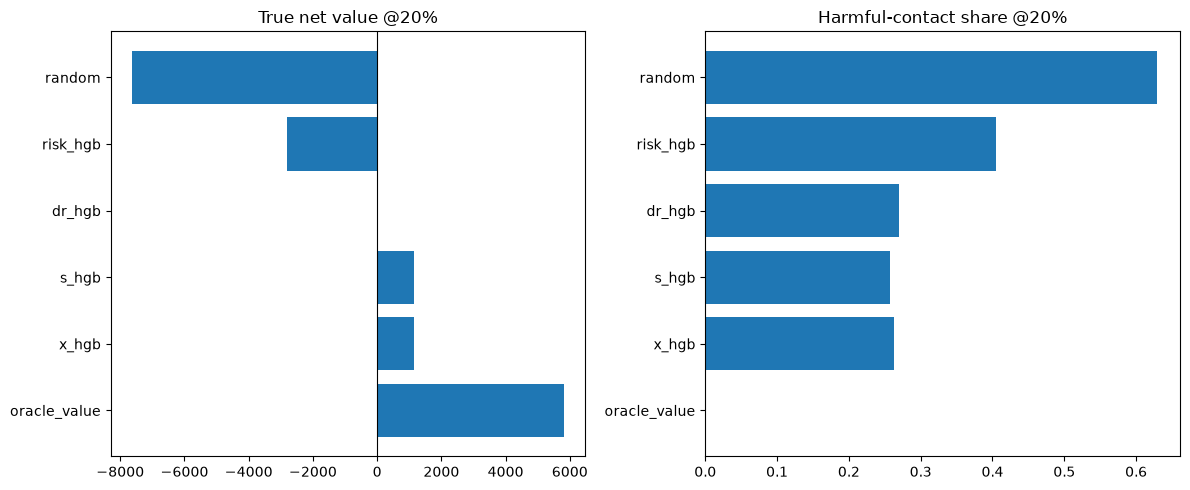

In [7]:
comparison = at_20[at_20["policy"].isin(["risk_hgb", "s_hgb", "dr_hgb", "x_hgb",
                                                       "random", "oracle_value"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(comparison["policy"], comparison["true_net_value"])
axes[0].axvline(0, color="black", linewidth=.8)
axes[0].set_title("True net value @20%")
axes[1].barh(comparison["policy"], comparison["harmful_offer_share"])
axes[1].set_title("Harmful-contact share @20%")
plt.tight_layout()
plt.show()

## 5. Failure taxonomy và action

| Failure | Evidence | Correct action |
|---|---|---|
| Underpowered ATE | observed 0,275pp < MDE 1,112pp | larger/balanced RCT |
| Selected-arm event scarcity | 15 control churn events | collect control events; no launch |
| Estimator disagreement | IPW/DR sign differs for many policies | investigate overlap/nuisance; do not cherry-pick |
| Effect drift | mock ATE +0,649% → −0,105% | persistent control + rolling effect monitoring |
| Risk ≠ response | mock risk policy value −2.813 @20% | causal/value policy shadow test |
| Conservative opportunity cost | no-contact regret 6.806 vs oracle | continue randomized exploration with power target |
| Feature opacity | Orange PCA/factors anonymized | no causal reason codes/action playbook |

Decision tốt có thể là `NO_LAUNCH`; nhưng no-launch không đồng nghĩa ngừng học. Nó phải đi kèm sample-size
target, control allocation, treatment definition và next review date.